In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import os
import glob
from scipy.optimize import curve_fit
from typing import List

In [2]:
def minmax_by_group(
    df: pd.DataFrame,
    value_col: str,
    groupby: List[str],
    min_groupby: List[str],
    max_groupby: List[str],
    min_query: str,
    max_query: str,
    new_col: str = "normalized"
) -> pd.DataFrame:

    out = df.copy()

    min_vals = (
        out.query(min_query)
        .groupby(min_groupby, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "min_val"})
    )

    max_vals = (
        out.query(max_query)
        .groupby(max_groupby, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "max_val"})
    )

    out = out.merge(min_vals, on=min_groupby, how="left")
    out = out.merge(max_vals, on=max_groupby, how="left")

    denom = out["max_val"] - out["min_val"]
    out[new_col] = (out[value_col] - out["min_val"]) / denom * 100
    out.loc[denom == 0, new_col] = np.nan

    return out

In [3]:
data_sumN = pd.read_table("NIPBL_data_2.txt")
data_sumN = data_sumN[data_sumN["rep"].isin([2,3,4,5,6,7])] #With paired Halo experiment
guides = ["206", "409", "848"]

In [4]:
data_normN = minmax_by_group(
    data_sumN,
    value_col="median",
    groupby=["rep", "dose"],
    min_groupby=["rep"],
    max_groupby=["rep", "guide"],
    min_query="guide == 'NT'",
    max_query="dose == 0",
    new_col="percentage"
)

In [5]:
halo = pd.read_table("NIPBL_data_Halo.txt")
halo["guide"] = "NIPBL protein"

206:ln2/(b)=11.678552713172552, c=57.52006784875702
409:ln2/(b)=7.407422136904062, c=44.374903539089374
848:ln2/(b)=6.311682272103594, c=27.59054726587155
NIPBL protein:ln2/(b)=3.7859300459220573, c=13.782592236597338


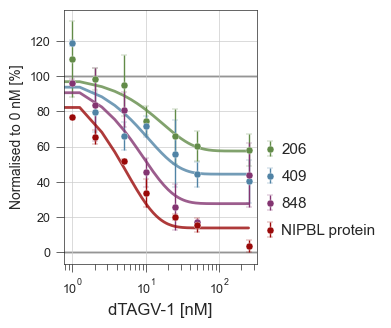

In [6]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

order = [0, 1, 2, 5, 10, 25, 50, 250]
hue_order=[x for x in guides] + ["NIPBL protein"]

def exp_decay(x, a, b):
    return a * np.exp(-b * x) + (100 - a)

x_fit = np.linspace(min(order), max(order), 200)

df = pd.concat([data_normN, halo])
df = df[(df["N"] >= 100)]

#Aggregate for each dose/guide combo
df_summary = (
    df.groupby(["dose", "guide"], as_index=False)
      .agg(mean_percentage=("percentage", "mean"),
           sd_percentage=("percentage", "std"))
)

dose_order = pd.DataFrame({"dose": order})
df_summary = (
    dose_order.merge(df_summary, on="dose", how="left")
)

palette = ['#628b48', '#5083a5',  '#833471',  '#9A0909']

fig, ax = plt.subplots(figsize=(2.5,3.3))

#Plot and fit exponential decay from y=100
for i, guide in enumerate(hue_order):
    sub = df_summary[df_summary["guide"] == guide]

    ax.errorbar(
        sub["dose"], sub["mean_percentage"],
        yerr=sub["sd_percentage"],
        fmt="o", ms=5,
        color=palette[i], label=guide,
        capsize=2, lw=1, 
        markeredgecolor="white",
        markeredgewidth=0.25,
    )
    try:
        popt, _ = curve_fit(exp_decay,
                            sub["dose"].values, sub["mean_percentage"].values,
                            p0=[300, 0.01])
        y_fit = exp_decay(x_fit, *popt)
        ax.plot(x_fit, y_fit, color=palette[i], lw=2, alpha=0.8)
        print(f"{guide}:ln2/(b)={np.log(2)/popt[1]}, c={100-popt[0]}")
    except RuntimeError:
        print(f"Fit failed for {guide}")
        continue

ax.set_xscale("log")
ax.set_xlabel("dTAGV-1 [nM]",)
ax.set_ylabel("Normalised to 0 nM [%]", fontsize=10)
ax.tick_params(labelsize=9)


ax.grid(True, linewidth=0.5)
ax.legend(title="", loc="upper right", bbox_to_anchor=(1.68,0.53), frameon=False, handletextpad=-0.25, labelspacing=0.85)
ax.axhline(100,color="k", zorder=-1, linewidth=1)
ax.axhline(0,color="k", zorder=-1, linewidth=1)

In [7]:
data_sumW = pd.read_table("WAPL_data_2.txt")
guides = ["409", "848"]

In [8]:
data_normW = minmax_by_group(
    data_sumW,
    value_col="median",
    groupby=["rep", "dose"],
    min_groupby=["rep"],
    max_groupby=["rep", "guide"],
    min_query="guide == 'NT'",
    max_query="dose == 0",
    new_col="percentage"
)

In [9]:
halo = pd.read_table("WAPL_data_Halo.txt")
halo["guide"] = "WAPL protein"

409:ln2/(b)=40.096511563985935, c=39.890129597220565
848:ln2/(b)=28.963116660795436, c=273.05491420612
WAPL protein:ln2/(b)=1.4585006630283452, c=9.068184545229286


/local/55263823.1.igmm_long/ipykernel_1276313/93400855.py:25: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  dose_order.merge(df_summary, on="dose", how="left")


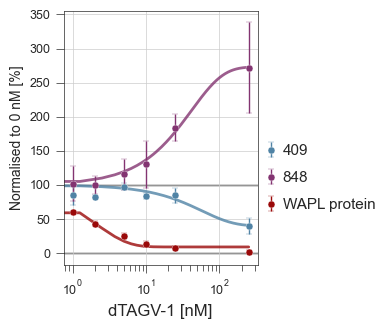

In [10]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

order = [0, 1, 2, 5, 10, 25, 50, 250]
hue_order=[x for x in guides] + ["WAPL protein"]

def exp_decay(x, a, b):
    return a * np.exp(-b * x) + (100 - a)

x_fit = np.linspace(min(order), max(order), 200)

df = pd.concat([data_normW, halo])
df = df[(df["N"] >= 100)]

#Aggregate for each dose/guide combo
df_summary = (
    df.groupby(["dose", "guide"], as_index=False)
      .agg(mean_percentage=("percentage", "mean"),
           sd_percentage=("percentage", "std"))
)

dose_order = pd.DataFrame({"dose": order})
df_summary = (
    dose_order.merge(df_summary, on="dose", how="left")
)

palette = ['#628b48', '#5083a5',  '#833471',  '#9A0909']

fig, ax = plt.subplots(figsize=(2.5,3.3))

#Plot and fit exponential decay from y=100
for i, guide in enumerate(hue_order):
    sub = df_summary[df_summary["guide"] == guide]

    ax.errorbar(
        sub["dose"], sub["mean_percentage"],
        yerr=sub["sd_percentage"],
        fmt="o", ms=5,
        color=palette[i+1], label=guide,
        capsize=2, lw=1, 
        markeredgecolor="white",
        markeredgewidth=0.25,
    )
    try:
        popt, _ = curve_fit(exp_decay,
                            sub["dose"].values, sub["mean_percentage"].values,
                            p0=[300, 0.01])
        y_fit = exp_decay(x_fit, *popt)
        ax.plot(x_fit, y_fit, color=palette[i+1], lw=2, alpha=0.8)
        print(f"{guide}:ln2/(b)={np.log(2)/popt[1]}, c={100-popt[0]}")
    except RuntimeError:
        print(f"Fit failed for {guide}")
        continue

ax.set_xscale("log")
ax.set_xlabel("dTAGV-1 [nM]",)
ax.set_ylabel("Normalised to 0 nM [%]", fontsize=10)
ax.tick_params(labelsize=9)


ax.grid(True, linewidth=0.5)
ax.legend(title="", loc="upper right", bbox_to_anchor=(1.68,0.53), frameon=False, handletextpad=-0.25, labelspacing=0.85)
ax.axhline(100,color="k", zorder=-1, linewidth=1)
ax.axhline(0,color="k", zorder=-1, linewidth=1)